## 1. Project Overview and Business Case

## 2. Dataset Loading and Quality Checks

In [1]:
from google.colab import files

uploaded = files.upload()

Saving BBC News Train.csv to BBC News Train.csv


In [2]:

import pandas as pd

df = pd.read_csv("BBC News Train.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("Column names:", df.columns.tolist())
display(df.head())


Dataset loaded successfully!
Dataset shape: (1490, 3)
Column names: ['ArticleId', 'Text', 'Category']


,ArticleId,Text,Category
0,1833,worldcom ex-boss launches defence lawyers defe...,business
1,154,german business confidence slides german busin...,business
2,1101,bbc poll indicates economic gloom citizens in ...,business
3,1976,lifestyle governs mobile choice faster bett...,tech
4,917,enron bosses in $168m payout eighteen former e...,business


In [3]:

# Check for missing values
print("Missing values in each column:")
print(df.isnull().sum())

# Count articles in each category
print("\nArticles per category:")
print(df["Category"].value_counts())

# Check for duplicate articles
print("\nDuplicate article texts:", df["Text"].duplicated().sum())


Missing values in each column:
ArticleId    0
Text         0
Category     0
dtype: int64

Articles per category:
Category
sport            346
business         336
politics         274
entertainment    273
tech             261
Name: count, dtype: int64

Duplicate article texts: 50


In [4]:

# Find duplicate article texts
duplicates = df[df["Text"].duplicated(keep=False)]

print("Total rows involved in duplicate texts:", len(duplicates))
display(duplicates[["ArticleId", "Category", "Text"]].head(10))


Total rows involved in duplicate texts: 100


,ArticleId,Category,Text
35,687,entertainment,musical treatment for capra film the classic f...
62,476,entertainment,prince crowned top music earner prince earne...
63,2017,tech,what high-definition will do to dvds first it ...
71,2144,tech,camera phones are must-haves four times more...
102,1680,tech,security warning over fbi virus the us feder...
105,777,politics,talks aim to avert pension strike talks aimed ...
123,39,politics,debate needed on donations cap a cap on donat...
157,853,entertainment,prince crowned top music earner prince earne...
161,840,tech,format wars could confuse users technology f...
193,828,politics,brown outlines third term vision gordon brown ...


In [5]:

# Remove rows with identical article text
df_clean = df.drop_duplicates(subset="Text", keep="first").copy()

print("Original dataset size:", len(df))
print("Dataset size after removing duplicates:", len(df_clean))
print("Duplicate texts remaining:", df_clean["Text"].duplicated().sum())
print("\nCategory distribution after cleaning:")
print(df_clean["Category"].value_counts())


Original dataset size: 1490
Dataset size after removing duplicates: 1440
Duplicate texts remaining: 0

Category distribution after cleaning:
Category
sport            342
business         335
politics         266
entertainment    263
tech             234
Name: count, dtype: int64


## 3. Text Preprocessing and TF-IDF

In [6]:

# Create a cleaned text column
df_clean["Clean_Text"] = (
    df_clean["Text"]
    .str.lower()
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
)

# Compare original and cleaned text
display(df_clean[["Text", "Clean_Text"]].head(5))

print("Missing cleaned texts:", df_clean["Clean_Text"].isnull().sum())


,Text,Clean_Text
0,worldcom ex-boss launches defence lawyers defe...,worldcom ex-boss launches defence lawyers defe...
1,german business confidence slides german busin...,german business confidence slides german busin...
2,bbc poll indicates economic gloom citizens in ...,bbc poll indicates economic gloom citizens in ...
3,lifestyle governs mobile choice faster bett...,lifestyle governs mobile choice faster better ...
4,enron bosses in $168m payout eighteen former e...,enron bosses in $168m payout eighteen former e...


Missing cleaned texts: 0


In [7]:

!pip install nltk


In [8]:

import nltk

nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

print("NLTK resources are ready!")


[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


NLTK resources are ready!


In [9]:

from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords

# Select the first cleaned article
sample_text = df_clean["Clean_Text"].iloc[0]

# Tokenize the article
tokens = word_tokenize(sample_text)

# Load English stop words
stop_words = set(stopwords.words("english"))

# Remove stop words and punctuation-only tokens
filtered_tokens = [
    word for word in tokens
    if word.isalpha() and word not in stop_words
]

print("Original text:")
print(sample_text[:300])

print("\nFirst 30 tokens:")
print(tokens[:30])

print("\nFirst 30 tokens after stop-word removal:")
print(filtered_tokens[:30])


Original text:
worldcom ex-boss launches defence lawyers defending former worldcom chief bernie ebbers against a battery of fraud charges have called a company whistleblower as their first witness. cynthia cooper worldcom s ex-head of internal accounting alerted directors to irregular accounting practices at the u

First 30 tokens:
['worldcom', 'ex-boss', 'launches', 'defence', 'lawyers', 'defending', 'former', 'worldcom', 'chief', 'bernie', 'ebbers', 'against', 'a', 'battery', 'of', 'fraud', 'charges', 'have', 'called', 'a', 'company', 'whistleblower', 'as', 'their', 'first', 'witness', '.', 'cynthia', 'cooper', 'worldcom']

First 30 tokens after stop-word removal:
['worldcom', 'launches', 'defence', 'lawyers', 'defending', 'former', 'worldcom', 'chief', 'bernie', 'ebbers', 'battery', 'fraud', 'charges', 'called', 'company', 'whistleblower', 'first', 'witness', 'cynthia', 'cooper', 'worldcom', 'internal', 'accounting', 'alerted', 'directors', 'irregular', 'accounting', 'practices', 'u

In [10]:

from nltk.stem import WordNetLemmatizer

# Create the lemmatizer
lemmatizer = WordNetLemmatizer()

# Lemmatize the filtered tokens
lemmatized_tokens = [
    lemmatizer.lemmatize(word)
    for word in filtered_tokens
]

print("Before lemmatization:")
print(filtered_tokens[:30])

print("\nAfter lemmatization:")
print(lemmatized_tokens[:30])


Before lemmatization:
['worldcom', 'launches', 'defence', 'lawyers', 'defending', 'former', 'worldcom', 'chief', 'bernie', 'ebbers', 'battery', 'fraud', 'charges', 'called', 'company', 'whistleblower', 'first', 'witness', 'cynthia', 'cooper', 'worldcom', 'internal', 'accounting', 'alerted', 'directors', 'irregular', 'accounting', 'practices', 'us', 'telecoms']

After lemmatization:
['worldcom', 'launch', 'defence', 'lawyer', 'defending', 'former', 'worldcom', 'chief', 'bernie', 'ebbers', 'battery', 'fraud', 'charge', 'called', 'company', 'whistleblower', 'first', 'witness', 'cynthia', 'cooper', 'worldcom', 'internal', 'accounting', 'alerted', 'director', 'irregular', 'accounting', 'practice', 'u', 'telecom']


In [11]:

from nltk.tokenize import word_tokenize

# Tokenize the cleaned article text
df_clean["Tokens"] = df_clean["Clean_Text"].apply(word_tokenize)

# Display the results
display(df_clean[["Clean_Text", "Tokens"]].head())

print("Tokenization completed successfully!")


,Clean_Text,Tokens
0,worldcom ex-boss launches defence lawyers defe...,"[worldcom, ex-boss, launches, defence, lawyers..."
1,german business confidence slides german busin...,"[german, business, confidence, slides, german,..."
2,bbc poll indicates economic gloom citizens in ...,"[bbc, poll, indicates, economic, gloom, citize..."
3,lifestyle governs mobile choice faster better ...,"[lifestyle, governs, mobile, choice, faster, b..."
4,enron bosses in $168m payout eighteen former e...,"[enron, bosses, in, $, 168m, payout, eighteen,..."


Tokenization completed successfully!


In [12]:

from nltk.corpus import stopwords

# Get English stopwords
stop_words = set(stopwords.words("english"))

# Remove stopwords from each article
df_clean["Filtered_Tokens"] = df_clean["Tokens"].apply(
    lambda tokens: [
        word for word in tokens
        if word.isalpha() and word not in stop_words
    ]
)

# Display the results
display(
    df_clean[["Tokens", "Filtered_Tokens"]].head()
)

print("Stopword removal completed successfully!")


,Tokens,Filtered_Tokens
0,"[worldcom, ex-boss, launches, defence, lawyers...","[worldcom, launches, defence, lawyers, defendi..."
1,"[german, business, confidence, slides, german,...","[german, business, confidence, slides, german,..."
2,"[bbc, poll, indicates, economic, gloom, citize...","[bbc, poll, indicates, economic, gloom, citize..."
3,"[lifestyle, governs, mobile, choice, faster, b...","[lifestyle, governs, mobile, choice, faster, b..."
4,"[enron, bosses, in, $, 168m, payout, eighteen,...","[enron, bosses, payout, eighteen, former, enro..."


Stopword removal completed successfully!


In [13]:

from nltk.stem import PorterStemmer

# Create a stemmer
stemmer = PorterStemmer()

# Apply stemming to filtered tokens
df_clean["Stemmed_Tokens"] = df_clean["Filtered_Tokens"].apply(
    lambda tokens: [stemmer.stem(word) for word in tokens]
)

# Compare the results
display(
    df_clean[["Filtered_Tokens", "Stemmed_Tokens"]].head()
)

print("Stemming completed successfully!")


,Filtered_Tokens,Stemmed_Tokens
0,"[worldcom, launches, defence, lawyers, defendi...","[worldcom, launch, defenc, lawyer, defend, for..."
1,"[german, business, confidence, slides, german,...","[german, busi, confid, slide, german, busi, co..."
2,"[bbc, poll, indicates, economic, gloom, citize...","[bbc, poll, indic, econom, gloom, citizen, maj..."
3,"[lifestyle, governs, mobile, choice, faster, b...","[lifestyl, govern, mobil, choic, faster, bette..."
4,"[enron, bosses, payout, eighteen, former, enro...","[enron, boss, payout, eighteen, former, enron,..."


Stemming completed successfully!


In [14]:

from nltk.stem import WordNetLemmatizer

# Create the lemmatizer
lemmatizer = WordNetLemmatizer()

# Lemmatize filtered tokens
df_clean["Lemmatized_Tokens"] = df_clean["Filtered_Tokens"].apply(
    lambda tokens: [
        lemmatizer.lemmatize(word)
        for word in tokens
    ]
)

# Display before and after
display(
    df_clean[["Filtered_Tokens", "Lemmatized_Tokens"]].head()
)

print("Lemmatization completed successfully!")


,Filtered_Tokens,Lemmatized_Tokens
0,"[worldcom, launches, defence, lawyers, defendi...","[worldcom, launch, defence, lawyer, defending,..."
1,"[german, business, confidence, slides, german,...","[german, business, confidence, slide, german, ..."
2,"[bbc, poll, indicates, economic, gloom, citize...","[bbc, poll, indicates, economic, gloom, citize..."
3,"[lifestyle, governs, mobile, choice, faster, b...","[lifestyle, governs, mobile, choice, faster, b..."
4,"[enron, bosses, payout, eighteen, former, enro...","[enron, boss, payout, eighteen, former, enron,..."


Lemmatization completed successfully!


In [15]:

# Join lemmatized tokens back into text
df_clean["Processed_Text"] = df_clean["Lemmatized_Tokens"].apply(
    lambda tokens: " ".join(tokens)
)

# Compare original and processed text
display(
    df_clean[["Text", "Processed_Text", "Category"]].head(5)
)

print("Processed text created successfully!")
print("Number of articles:", len(df_clean))
print("Missing processed texts:", df_clean["Processed_Text"].isnull().sum())


,Text,Processed_Text,Category
0,worldcom ex-boss launches defence lawyers defe...,worldcom launch defence lawyer defending forme...,business
1,german business confidence slides german busin...,german business confidence slide german busine...,business
2,bbc poll indicates economic gloom citizens in ...,bbc poll indicates economic gloom citizen majo...,business
3,lifestyle governs mobile choice faster bett...,lifestyle governs mobile choice faster better ...,tech
4,enron bosses in $168m payout eighteen former e...,enron boss payout eighteen former enron direct...,business


Processed text created successfully!
Number of articles: 1440
Missing processed texts: 0


In [16]:

from sklearn.feature_extraction.text import TfidfVectorizer

# Create the TF-IDF vectorizer
tfidf = TfidfVectorizer(
    max_features=3000,
    min_df=2,
    max_df=0.95
)

# Convert processed articles into TF-IDF features
X_tfidf = tfidf.fit_transform(df_clean["Processed_Text"])

print("TF-IDF extraction completed!")
print("Number of articles:", X_tfidf.shape[0])
print("Number of features:", X_tfidf.shape[1])
print("Matrix format:", type(X_tfidf).__name__)


TF-IDF extraction completed!
Number of articles: 1440
Number of features: 3000
Matrix format: csr_matrix


In [17]:

import pandas as pd

# Get the vocabulary learned by TF-IDF
terms = tfidf.get_feature_names_out()

# Calculate each term's average TF-IDF score
mean_scores = X_tfidf.mean(axis=0).A1

# Create a table of terms and scores
tfidf_scores = pd.DataFrame({
    "Word": terms,
    "Mean_TFIDF": mean_scores
})

# Display the 20 highest-scoring terms
top_words = tfidf_scores.sort_values(
    by="Mean_TFIDF",
    ascending=False
).head(20)

display(top_words)


,Word,Mean_TFIDF
2313,said,0.048793
1734,mr,0.031841
2989,year,0.025526
2978,would,0.023062
1029,film,0.022513
1115,game,0.020509
1770,new,0.020111
1912,people,0.019624
99,also,0.019525
1820,one,0.017523


In [18]:

from sklearn.feature_extraction.text import TfidfVectorizer
import pandas as pd

# Analyze the most informative terms within each category
for category in sorted(df_clean["Category"].unique()):
    category_text = df_clean.loc[
        df_clean["Category"] == category, "Processed_Text"
    ]

    category_vectorizer = TfidfVectorizer(
        max_features=1000,
        min_df=2,
        max_df=0.95
    )

    category_matrix = category_vectorizer.fit_transform(category_text)

    terms = category_vectorizer.get_feature_names_out()
    scores = category_matrix.mean(axis=0).A1

    top_terms = pd.DataFrame({
        "Word": terms,
        "Mean_TFIDF": scores
    }).sort_values("Mean_TFIDF", ascending=False).head(10)

    print(f"\nTop words for {category}:")
    display(top_terms)




Top words for business:


,Word,Mean_TFIDF
787,said,0.064133
992,year,0.040924
328,firm,0.036630
593,mr,0.035622
170,company,0.035500
788,sale,0.033872
554,market,0.030665
72,bank,0.030558
392,growth,0.030278
818,share,0.029772



Top words for entertainment:


,Word,Mean_TFIDF
347,film,0.080528
774,said,0.053944
96,best,0.050632
75,award,0.045450
996,year,0.038865
811,show,0.038443
604,music,0.034168
82,band,0.030578
851,star,0.030152
37,also,0.029876



Top words for politics:


,Word,Mean_TFIDF
770,said,0.091169
570,mr,0.081868
473,labour,0.051717
286,election,0.049356
994,would,0.048096
109,blair,0.046026
627,party,0.045287
121,brown,0.039440
881,tax,0.038201
380,government,0.037762



Top words for sport:


,Word,Mean_TFIDF
756,said,0.047421
349,game,0.039328
276,england,0.038195
976,win,0.030092
990,world,0.030056
660,player,0.029482
995,year,0.029048
323,first,0.028879
546,match,0.026778
488,last,0.026626



Top words for tech:


,Word,Mean_TFIDF
751,said,0.064744
355,game,0.050003
642,phone,0.047500
566,mobile,0.047450
637,people,0.045297
781,service,0.036164
881,technology,0.032854
580,mr,0.031837
591,net,0.030527
936,user,0.030401


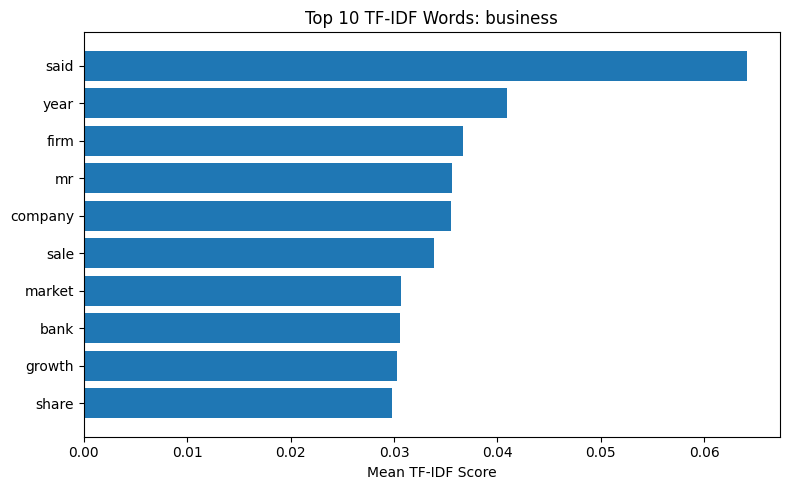

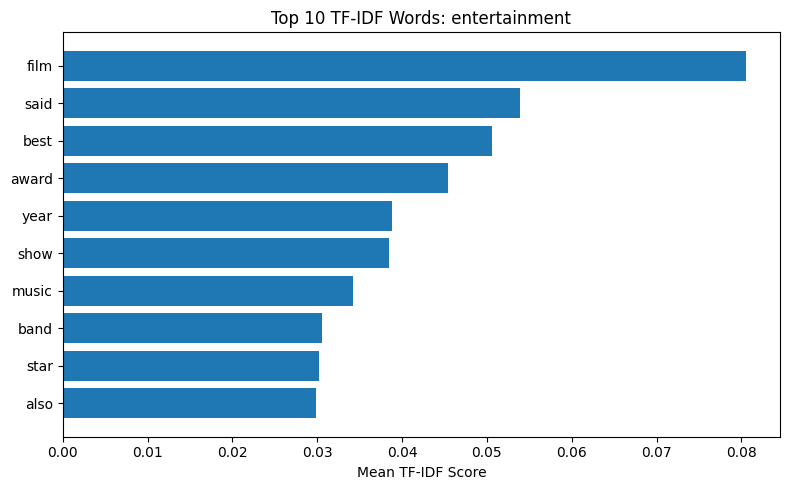

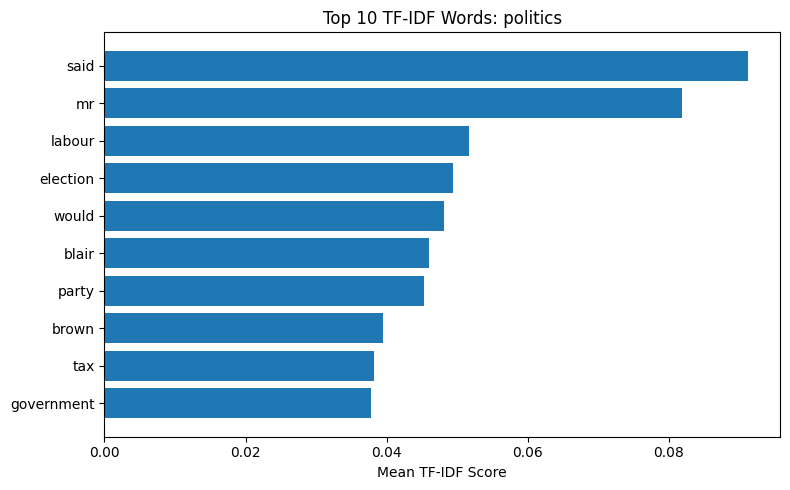

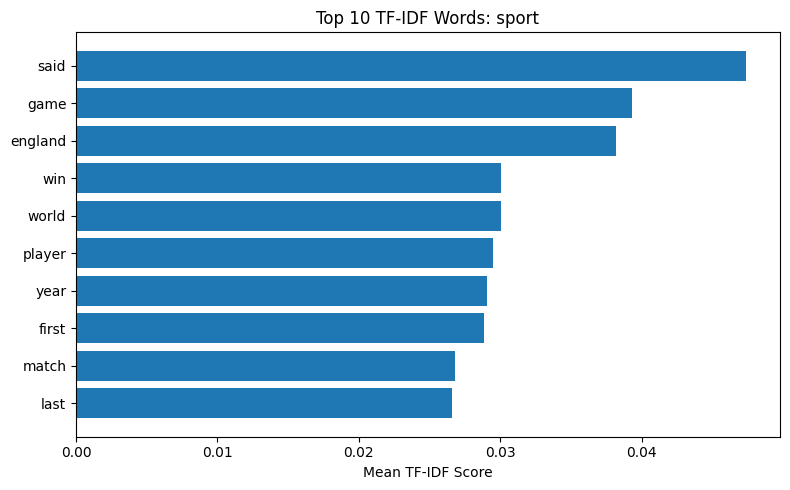

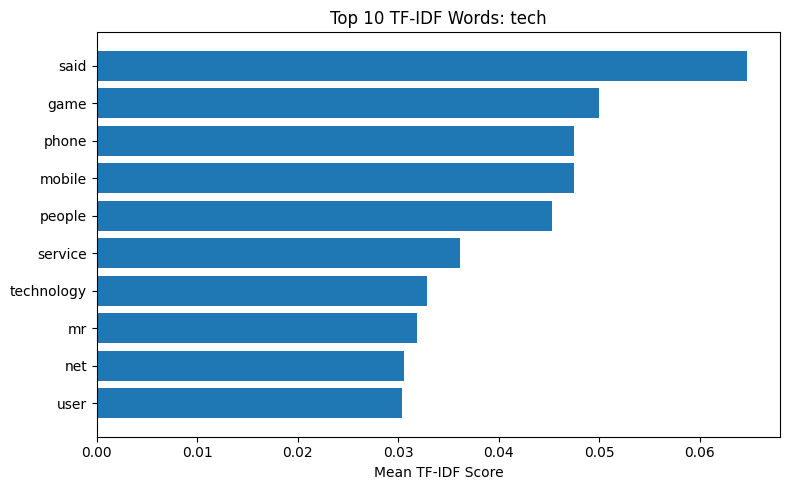

In [19]:
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer

for category in sorted(df_clean["Category"].unique()):
    category_text = df_clean.loc[
        df_clean["Category"] == category, "Processed_Text"
    ]

    vectorizer = TfidfVectorizer(
        max_features=1000,
        min_df=2,
        max_df=0.95
    )

    matrix = vectorizer.fit_transform(category_text)
    terms = vectorizer.get_feature_names_out()
    scores = matrix.mean(axis=0).A1

    top_indices = scores.argsort()[-10:]

    plt.figure(figsize=(8, 5))
    plt.barh(terms[top_indices], scores[top_indices])
    plt.title(f"Top 10 TF-IDF Words: {category}")
    plt.xlabel("Mean TF-IDF Score")
    plt.tight_layout()
    plt.show()

## 4. Linguistic Analysis


In [20]:
import nltk
from nltk import pos_tag, word_tokenize

nltk.download('averaged_perceptron_tagger_eng')

# Select one news article
sample_text = df_clean["Clean_Text"].iloc[0]

# Tokenize and tag each word
tokens = word_tokenize(sample_text)
tagged_words = pos_tag(tokens)

# Display the first 30 words and their tags
print("Sample POS Tags:")
print(tagged_words[:30])

[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger_eng.zip.


Sample POS Tags:
[('worldcom', 'JJ'), ('ex-boss', 'JJ'), ('launches', 'NNS'), ('defence', 'NN'), ('lawyers', 'NNS'), ('defending', 'VBG'), ('former', 'JJ'), ('worldcom', 'NN'), ('chief', 'NN'), ('bernie', 'NN'), ('ebbers', 'NNS'), ('against', 'IN'), ('a', 'DT'), ('battery', 'NN'), ('of', 'IN'), ('fraud', 'NN'), ('charges', 'NNS'), ('have', 'VBP'), ('called', 'VBN'), ('a', 'DT'), ('company', 'NN'), ('whistleblower', 'NN'), ('as', 'IN'), ('their', 'PRP$'), ('first', 'JJ'), ('witness', 'NN'), ('.', '.'), ('cynthia', 'VB'), ('cooper', 'JJ'), ('worldcom', 'NN')]


In [21]:
from collections import Counter
import pandas as pd

# Count the POS tags
pos_counts = Counter(tag for word, tag in tagged_words)

# Display the 10 most common tags
pos_summary = pd.DataFrame(
    pos_counts.most_common(10),
    columns=["POS Tag", "Count"]
)

display(pos_summary)

,POS Tag,Count
0,NN,73
1,NNS,36
2,IN,35
3,JJ,28
4,DT,21
5,VBD,19
6,VBN,13
7,.,12
8,TO,10
9,VB,9


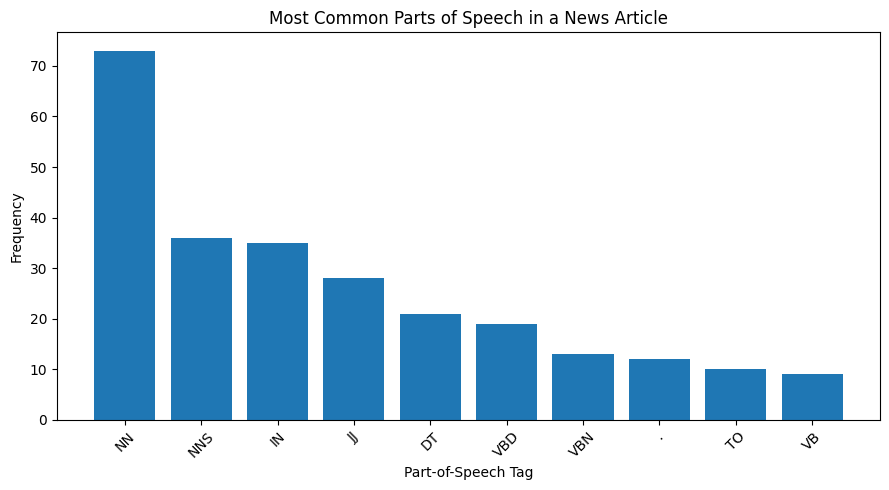

In [22]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))
plt.bar(pos_summary["POS Tag"], pos_summary["Count"])

plt.title("Most Common Parts of Speech in a News Article")
plt.xlabel("Part-of-Speech Tag")
plt.ylabel("Frequency")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [23]:
!pip install spacy
!python -m spacy download en_core_web_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 94.3 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [24]:
import spacy
import pandas as pd

# Load the English language model
nlp = spacy.load("en_core_web_sm")

# Select a short sample from your dataset
sample_text = df_clean["Clean_Text"].iloc[0][:1000]

# Analyze the sentence structure
doc = nlp(sample_text)

# Display word relationships
dependency_results = pd.DataFrame([
    {
        "Word": token.text,
        "Part of Speech": token.pos_,
        "Dependency": token.dep_,
        "Head Word": token.head.text
    }
    for token in doc
    if not token.is_space
])

display(dependency_results.head(30))

,Word,Part of Speech,Dependency,Head Word
0,worldcom,PROPN,compound,launches
1,ex,PROPN,compound,launches
2,-,NOUN,nsubj,launches
3,boss,NOUN,nsubj,launches
4,launches,VERB,ROOT,launches
5,defence,NOUN,compound,lawyers
6,lawyers,NOUN,dobj,launches
7,defending,VERB,acl,lawyers
8,former,ADJ,amod,ebbers
9,worldcom,PROPN,compound,ebbers


In [25]:
from spacy import displacy

# Select the first complete sentence
first_sentence = next(doc.sents)

# Display the dependency diagram
displacy.render(
    first_sentence,
    style="dep",
    jupyter=True,
    options={"compact": True, "distance": 100}
)

In [26]:
import pandas as pd

# Extract meaningful information from the spaCy document
semantic_results = pd.DataFrame([
    {
        "Text": chunk.text,
        "Root Word": chunk.root.text,
        "Root POS": chunk.root.pos_,
        "Phrase Type": chunk.root.dep_
    }
    for chunk in doc.noun_chunks
])

display(semantic_results.head(20))

,Text,Root Word,Root POS,Phrase Type
0,-,-,NOUN,nsubj
1,boss,boss,NOUN,nsubj
2,defence lawyers,lawyers,NOUN,dobj
3,former worldcom chief bernie ebbers,ebbers,NOUN,dobj
4,a battery,battery,NOUN,pobj
5,fraud charges,charges,NOUN,pobj
6,a company,company,NOUN,dobj
7,their first witness,witness,NOUN,pobj
8,cynthia cooper worldcom,worldcom,PROPN,nsubj
9,ex,ex,NOUN,attr


In [27]:
!pip install vaderSentiment

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.0/126.0 kB 2.3 MB/s eta 0:00:00


In [28]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
import pandas as pd

# Create the sentiment analyzer
analyzer = SentimentIntensityAnalyzer()

# Analyze one news article
sample_text = df_clean["Clean_Text"].iloc[0]
sentiment_scores = analyzer.polarity_scores(sample_text)

# Display the results
sentiment_results = pd.DataFrame([sentiment_scores])
display(sentiment_results)

# Classify the overall sentiment
compound = sentiment_scores["compound"]

if compound >= 0.05:
    sentiment = "Positive"
elif compound <= -0.05:
    sentiment = "Negative"
else:
    sentiment = "Neutral"

print("Overall Sentiment:", sentiment)

,neg,neu,pos,compound
0,0.13,0.806,0.064,-0.9609


Overall Sentiment: Negative


## 5. Sentiment and Emotion Analysis

In [30]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
import pandas as pd

analyzer = SentimentIntensityAnalyzer()

scores = []
total = len(df_clean)

for i, text in enumerate(df_clean["Clean_Text"]):
    scores.append(analyzer.polarity_scores(text)["compound"])

    if (i + 1) % 200 == 0:
        print(f"Processed {i + 1} of {total} articles")

df_clean["Sentiment_Compound"] = scores

df_clean["Sentiment"] = df_clean["Sentiment_Compound"].apply(
    lambda score: "Positive" if score >= 0.05
    else "Negative" if score <= -0.05
    else "Neutral"
)

sentiment_summary = pd.crosstab(
    df_clean["Category"],
    df_clean["Sentiment"]
)

display(sentiment_summary)

Processed 200 of 1440 articles
Processed 400 of 1440 articles
Processed 600 of 1440 articles
Processed 800 of 1440 articles
Processed 1000 of 1440 articles
Processed 1200 of 1440 articles
Processed 1400 of 1440 articles


Sentiment,Negative,Neutral,Positive
Category,,,
business,121,4,210
entertainment,47,4,212
politics,123,1,142
sport,68,1,273
tech,50,2,182


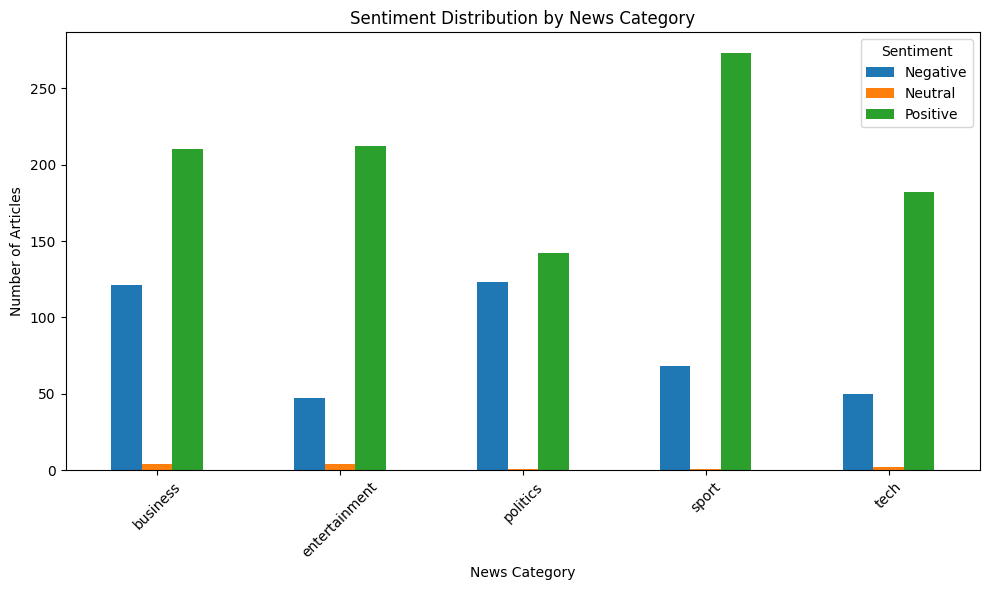

In [31]:
import matplotlib.pyplot as plt

sentiment_summary.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Sentiment Distribution by News Category")
plt.xlabel("News Category")
plt.ylabel("Number of Articles")
plt.xticks(rotation=45)
plt.legend(title="Sentiment")
plt.tight_layout()
plt.show()

In [32]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

# Input text and target labels
X = df_clean["Processed_Text"]
y = df_clean["Category"]

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Learn TF-IDF features from training data only
classifier_tfidf = TfidfVectorizer(
    max_features=5000,
    min_df=2,
    max_df=0.95
)

X_train_tfidf = classifier_tfidf.fit_transform(X_train)
X_test_tfidf = classifier_tfidf.transform(X_test)

print("Training articles:", X_train_tfidf.shape[0])
print("Testing articles:", X_test_tfidf.shape[0])
print("Number of TF-IDF features:", X_train_tfidf.shape[1])

Training articles: 1152
Testing articles: 288
Number of TF-IDF features: 5000


In [33]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# Create and train the model
lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train_tfidf, y_train)

# Predict categories for the test articles
y_pred = lr_model.predict(X_test_tfidf)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)

print(f"Model Accuracy: {accuracy:.2%}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Model Accuracy: 96.18%

Classification Report:
               precision    recall  f1-score   support

     business       0.93      0.99      0.96        67
entertainment       1.00      0.96      0.98        53
     politics       0.98      0.96      0.97        53
        sport       0.94      1.00      0.97        68
         tech       0.98      0.87      0.92        47

     accuracy                           0.96       288
    macro avg       0.97      0.96      0.96       288
 weighted avg       0.96      0.96      0.96       288



In [34]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report

# Create and train the model
nb_model = MultinomialNB()
nb_model.fit(X_train_tfidf, y_train)

# Predict news categories
nb_pred = nb_model.predict(X_test_tfidf)

# Evaluate the model
nb_accuracy = accuracy_score(y_test, nb_pred)

print(f"Naive Bayes Accuracy: {nb_accuracy:.2%}")
print("\nClassification Report:")
print(classification_report(y_test, nb_pred))

Naive Bayes Accuracy: 95.14%

Classification Report:
               precision    recall  f1-score   support

     business       0.92      0.97      0.94        67
entertainment       1.00      0.94      0.97        53
     politics       0.93      0.94      0.93        53
        sport       0.96      1.00      0.98        68
         tech       0.98      0.87      0.92        47

     accuracy                           0.95       288
    macro avg       0.96      0.95      0.95       288
 weighted avg       0.95      0.95      0.95       288



In [35]:
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score

# Compare both models
model_comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Naive Bayes"],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, nb_pred)
    ],
    "Weighted F1 Score": [
        f1_score(y_test, y_pred, average="weighted"),
        f1_score(y_test, nb_pred, average="weighted")
    ]
})

display(
    model_comparison.style.format({
        "Accuracy": "{:.2%}",
        "Weighted F1 Score": "{:.2%}"
    })
)

,Model,Accuracy,Weighted F1 Score
0,Logistic Regression,96.18%,96.15%
1,Naive Bayes,95.14%,95.12%


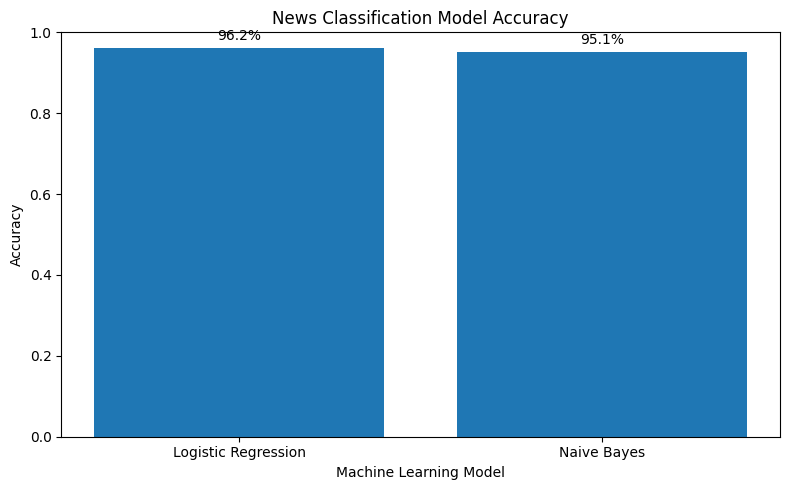

In [36]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    model_comparison["Model"],
    model_comparison["Accuracy"]
)

plt.title("News Classification Model Accuracy")
plt.xlabel("Machine Learning Model")
plt.ylabel("Accuracy")
plt.ylim(0, 1)

for i, value in enumerate(model_comparison["Accuracy"]):
    plt.text(i, value + 0.02, f"{value:.1%}", ha="center")

plt.tight_layout()
plt.show()

## 6. Named Entity Recognition (NER)

In [37]:
import spacy
import pandas as pd

# Load the English NLP model
nlp = spacy.load("en_core_web_sm")

# Select one news article
sample_text = df_clean["Clean_Text"].iloc[0][:3000]

# Identify named entities
doc_ner = nlp(sample_text)

# Organize the results
ner_results = pd.DataFrame([
    {
        "Entity": ent.text,
        "Entity Type": ent.label_,
        "Description": spacy.explain(ent.label_)
    }
    for ent in doc_ner.ents
])

display(ner_results.head(30))

,Entity,Entity Type,Description
0,first,ORDINAL,"""first"", ""second"", etc."
1,cynthia cooper,PERSON,"People, including fictional"
2,us,GPE,"Countries, cities, states"
3,2002,DATE,Absolute or relative dates or periods
4,5.7bn,MONEY,"Monetary values, including unit"
5,new york,GPE,"Countries, cities, states"
6,wednesday,DATE,Absolute or relative dates or periods
7,arthur andersen,PERSON,"People, including fictional"
8,early 2001 and,DATE,Absolute or relative dates or periods
9,2002,DATE,Absolute or relative dates or periods


In [38]:
from spacy import displacy

# Highlight named entities in the article
displacy.render(
    doc_ner,
    style="ent",
    jupyter=True
)

In [39]:
from collections import Counter
import pandas as pd

# Small emotion-word lists for an initial exploratory analysis
emotion_words = {
    "Joy": {"happy", "joy", "delight", "success", "love", "win", "celebrate"},
    "Anger": {"angry", "anger", "furious", "rage", "attack", "blame"},
    "Sadness": {"sad", "sorrow", "grief", "tragic", "death", "loss"},
    "Fear": {"fear", "afraid", "threat", "danger", "worry", "crisis"},
    "Surprise": {"surprise", "unexpected", "astonishing", "shock", "suddenly"}
}

def count_emotions(text):
    words = set(text.split())
    return {
        emotion: sum(word in words for word in vocabulary)
        for emotion, vocabulary in emotion_words.items()
    }

emotion_counts = df_clean["Processed_Text"].apply(count_emotions)

emotion_df = pd.DataFrame(emotion_counts.tolist(), index=df_clean.index)
df_clean[emotion_df.columns] = emotion_df

display(df_clean[["Category"] + list(emotion_words.keys())].head(10))

,Category,Joy,Anger,Sadness,Fear,Surprise
0,business,0,0,0,0,0
1,business,0,0,0,2,0
2,business,0,0,0,0,0
3,tech,0,0,0,0,0
4,business,0,0,0,0,0
5,politics,1,0,0,0,0
6,sport,1,1,0,1,0
7,entertainment,0,0,1,0,0
8,business,0,0,1,1,0
9,entertainment,1,0,0,0,0


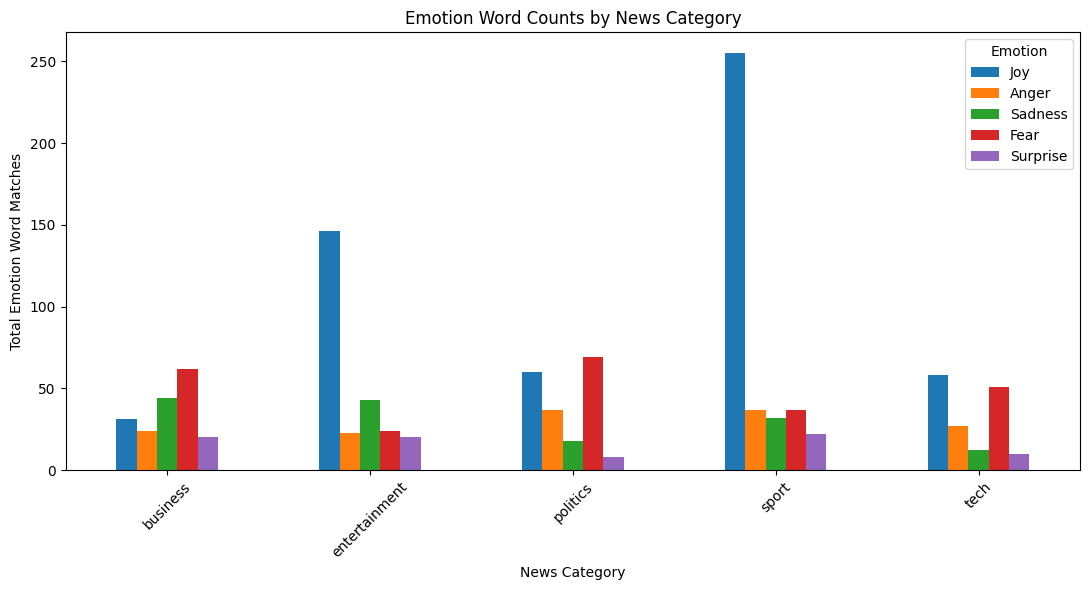

,Joy,Anger,Sadness,Fear,Surprise
Category,,,,,
business,31,24,44,62,20
entertainment,146,23,43,24,20
politics,60,37,18,69,8
sport,255,37,32,37,22
tech,58,27,12,51,10


In [40]:
import matplotlib.pyplot as plt

emotion_columns = ["Joy", "Anger", "Sadness", "Fear", "Surprise"]

emotion_by_category = df_clean.groupby("Category")[emotion_columns].sum()

emotion_by_category.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Emotion Word Counts by News Category")
plt.xlabel("News Category")
plt.ylabel("Total Emotion Word Matches")
plt.xticks(rotation=45)
plt.legend(title="Emotion")
plt.tight_layout()
plt.show()

display(emotion_by_category)

,Nouns,Verbs,Adjectives,Adverbs
Category,,,,
business,52.26,19.19,19.64,4.85
entertainment,51.16,18.62,20.81,4.87
politics,48.97,21.41,20.00,4.75
sport,49.17,19.54,20.38,5.65
tech,50.14,19.31,19.85,5.47


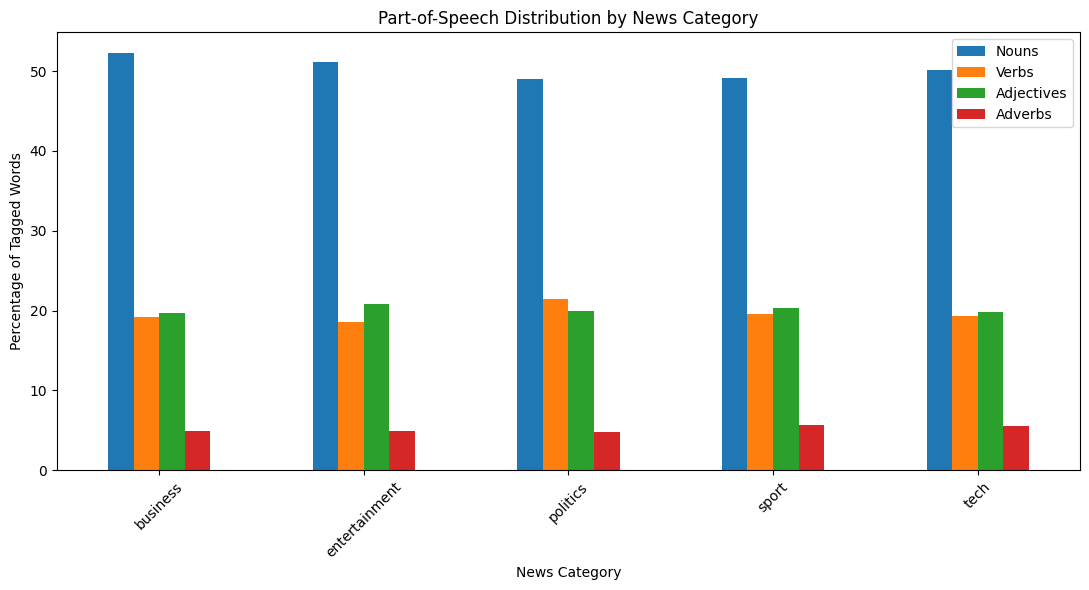

In [41]:
import pandas as pd
import matplotlib.pyplot as plt
import nltk
from nltk import pos_tag, word_tokenize

# Analyze a sample of articles from each category
sample_size = min(100, df_clean.groupby("Category").size().min())
pos_results = []

for category, group in df_clean.groupby("Category"):
    sample = group.sample(n=sample_size, random_state=42)

    counts = {"Nouns": 0, "Verbs": 0, "Adjectives": 0, "Adverbs": 0}
    total = 0

    for text in sample["Processed_Text"]:
        words = word_tokenize(text)
        tagged = pos_tag(words)

        for word, tag in tagged:
            total += 1
            if tag.startswith(("NN",)):
                counts["Nouns"] += 1
            elif tag.startswith("VB"):
                counts["Verbs"] += 1
            elif tag.startswith("JJ"):
                counts["Adjectives"] += 1
            elif tag.startswith("RB"):
                counts["Adverbs"] += 1

    # Convert counts to percentages for fair comparison
    pos_results.append({
        "Category": category,
        **{
            pos: round(count / total * 100, 2)
            for pos, count in counts.items()
        }
    })

pos_df = pd.DataFrame(pos_results).set_index("Category")

display(pos_df)

pos_df.plot(kind="bar", figsize=(11, 6))
plt.title("Part-of-Speech Distribution by News Category")
plt.xlabel("News Category")
plt.ylabel("Percentage of Tagged Words")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [42]:
from collections import Counter
import pandas as pd
from tqdm.auto import tqdm

tqdm.pandas()

# Extract named entities from every article
def extract_entities(text):
    doc = nlp(text)
    return [
        (ent.text, ent.label_)
        for ent in doc.ents
    ]

df_clean["Entities"] = df_clean["Clean_Text"].progress_apply(
    extract_entities
)

# Count entities by news category
entity_rows = []

for _, row in df_clean.iterrows():
    for entity, entity_type in row["Entities"]:
        entity_rows.append({
            "Category": row["Category"],
            "Entity": entity,
            "Entity Type": entity_type
        })

entity_df = pd.DataFrame(entity_rows)

# Display the most frequent entities in each category
for category in sorted(df_clean["Category"].unique()):
    print(f"\nTop 10 entities in {category} news:")

    category_entities = entity_df[
        entity_df["Category"] == category
    ]

    display(
        category_entities.groupby(
            ["Entity", "Entity Type"]
        ).size()
        .reset_index(name="Frequency")
        .sort_values("Frequency", ascending=False)
        .head(10)
    )

  0%|          | 0/1440 [00:00<?, ?it/s]


Top 10 entities in business news:


,Entity,Entity Type,Frequency
3882,us,GPE,243
1883,china,GPE,118
564,2004,DATE,111
2981,one,CARDINAL,108
568,2005,DATE,104
3799,two,CARDINAL,100
3830,uk,GPE,99
2573,last year,DATE,90
2323,india,GPE,76
563,2003,DATE,72



Top 10 entities in entertainment news:


,Entity,Entity Type,Frequency
1367,first,ORDINAL,145
2251,one,CARDINAL,142
1022,british,NORP,124
3013,uk,GPE,121
2995,two,CARDINAL,98
3027,us,GPE,96
933,bbc,ORG,89
2929,three,CARDINAL,78
1898,london,GPE,67
337,2004,DATE,66


...

,Entity,Entity Type,Frequency
767,britain,GPE,172
2152,uk,GPE,170
728,blair,PERSON,143
2123,tory,NORP,129
768,british,NORP,116
2135,two,CARDINAL,110
988,first,ORDINAL,107
2116,tony blair,PERSON,90
1584,one,CARDINAL,82
1438,michael howard,PERSON,72



Top 10 entities in sport news:


,Entity,Entity Type,Frequency
1348,first,ORDINAL,288
3167,two,CARDINAL,192
1384,france,GPE,149
2624,second,ORDINAL,144
2667,six,CARDINAL,133
3098,three,CARDINAL,115
2301,one,CARDINAL,113
1276,england,GPE,105
3069,third,ORDINAL,79
808,australian,NORP,75



Top 10 entities in tech news:


,Entity,Entity Type,Frequency
1668,one,CARDINAL,183
1072,first,ORDINAL,141
2260,us,GPE,130
2226,uk,GPE,125
1439,microsoft,ORG,102
2208,two,CARDINAL,84
1886,sony,ORG,83
1037,europe,LOC,75
240,2005,DATE,54
1038,european,NORP,49


## 7. Model Training and Optimization

In [43]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score, f1_score

# Test different Logistic Regression settings
param_grid = {
    "C": [0.1, 1, 10],
    "solver": ["lbfgs"],
    "max_iter": [1000]
}

grid_search = GridSearchCV(
    LogisticRegression(random_state=42),
    param_grid,
    cv=3,
    scoring="f1_weighted",
    n_jobs=-1
)

grid_search.fit(X_train_tfidf, y_train)

# Evaluate the best model on the held-out test data
best_model = grid_search.best_estimator_
optimized_pred = best_model.predict(X_test_tfidf)

print("Best parameters:", grid_search.best_params_)
print("Optimized test accuracy:", round(
    accuracy_score(y_test, optimized_pred), 4
))
print("Optimized weighted F1:", round(
    f1_score(y_test, optimized_pred, average="weighted"), 4
))

print("\nClassification report:")
print(classification_report(y_test, optimized_pred))

Best parameters: {'C': 10, 'max_iter': 1000, 'solver': 'lbfgs'}
Optimized test accuracy: 0.9618
Optimized weighted F1: 0.9616

Classification report:
               precision    recall  f1-score   support

     business       0.93      0.99      0.96        67
entertainment       1.00      0.96      0.98        53
     politics       0.98      0.94      0.96        53
        sport       0.94      1.00      0.97        68
         tech       0.98      0.89      0.93        47

     accuracy                           0.96       288
    macro avg       0.97      0.96      0.96       288
 weighted avg       0.96      0.96      0.96       288



In [44]:
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
import pandas as pd

models = {
    "Logistic Regression (Original)": y_pred,
    "Naive Bayes": nb_pred,
    "Logistic Regression (Optimized)": optimized_pred
}

comparison_results = []

for model_name, predictions in models.items():
    comparison_results.append({
        "Model": model_name,
        "Accuracy": round(accuracy_score(y_test, predictions), 4),
        "Weighted Precision": round(
            precision_score(y_test, predictions, average="weighted", zero_division=0), 4
        ),
        "Weighted Recall": round(
            recall_score(y_test, predictions, average="weighted", zero_division=0), 4
        ),
        "Weighted F1": round(
            f1_score(y_test, predictions, average="weighted", zero_division=0), 4
        )
    })

final_model_comparison = pd.DataFrame(comparison_results)
display(final_model_comparison)

,Model,Accuracy,Weighted Precision,Weighted Recall,Weighted F1
0,Logistic Regression (Original),0.9618,0.9631,0.9618,0.9615
1,Naive Bayes,0.9514,0.9528,0.9514,0.9512
2,Logistic Regression (Optimized),0.9618,0.9631,0.9618,0.9616


In [45]:
import pandas as pd

# Compare actual and predicted categories
error_analysis = pd.DataFrame({
    "Article": X_test.index,
    "Actual Category": y_test.values,
    "Predicted Category": optimized_pred
})

# Keep only incorrectly classified articles
errors = error_analysis[
    error_analysis["Actual Category"] !=
    error_analysis["Predicted Category"]
].copy()

print("Number of incorrect predictions:", len(errors))
print("Total test articles:", len(error_analysis))
print(
    "Error rate:",
    round(len(errors) / len(error_analysis) * 100, 2),
    "%"
)

display(errors.head(10))

Number of incorrect predictions: 11
Total test articles: 288
Error rate: 3.82 %


,Article,Actual Category,Predicted Category
1,1072,tech,business
17,404,business,politics
39,1152,politics,business
59,417,tech,sport
74,1071,entertainment,tech
76,249,politics,business
115,40,tech,business
130,540,tech,sport
140,346,entertainment,sport
243,498,tech,sport


## 8. Evaluation, Findings, and Conclusion

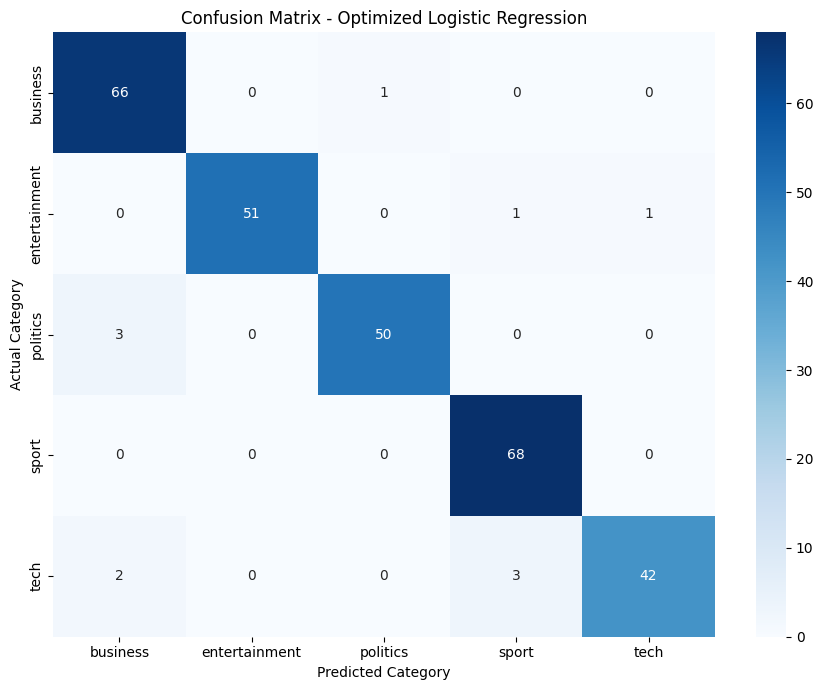

In [46]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
from sklearn.utils.multiclass import unique_labels

labels = sorted(y_test.unique())

cm = confusion_matrix(
    y_test,
    optimized_pred,
    labels=labels
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.title("Confusion Matrix - Optimized Logistic Regression")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.tight_layout()
plt.show()

In [47]:
import pandas as pd
from tqdm.auto import tqdm

tqdm.pandas()

# Analyze up to 100 articles per category
syntax_sample = (
    df_clean.groupby("Category", group_keys=False)
    .apply(lambda group: group.sample(
        n=min(100, len(group)), random_state=42
    ))
    .reset_index(drop=True)
)

syntax_results = []

for _, row in tqdm(syntax_sample.iterrows(),
                   total=len(syntax_sample)):
    doc = nlp(row["Clean_Text"][:1500])

    for token in doc:
        if not token.is_punct and not token.is_space:
            syntax_results.append({
                "Category": row["Category"],
                "Dependency": token.dep_,
                "POS": token.pos_
            })

syntax_df = pd.DataFrame(syntax_results)

# Compare the most frequent dependency relations
dependency_comparison = pd.crosstab(
    syntax_df["Category"],
    syntax_df["Dependency"],
    normalize="index"
) * 100

top_dependencies = (
    syntax_df["Dependency"].value_counts().head(8).index
)

display(dependency_comparison[top_dependencies].round(2))

/tmp/ipykernel_755/2825023146.py:9: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda group: group.sample(


  0%|          | 0/500 [00:00<?, ?it/s]

Dependency,prep,pobj,det,compound,nsubj,amod,dobj,aux
Category,,,,,,,,
business,11.44,10.89,9.50,8.65,7.90,7.42,4.78,4.64
entertainment,10.88,10.41,9.34,10.34,7.53,7.25,5.09,3.90
politics,9.99,9.61,9.18,8.94,8.90,6.50,5.57,5.90
sport,10.87,9.80,8.83,8.11,9.39,6.19,5.24,4.92
tech,10.72,10.28,9.34,7.79,7.96,7.71,5.60,5.30


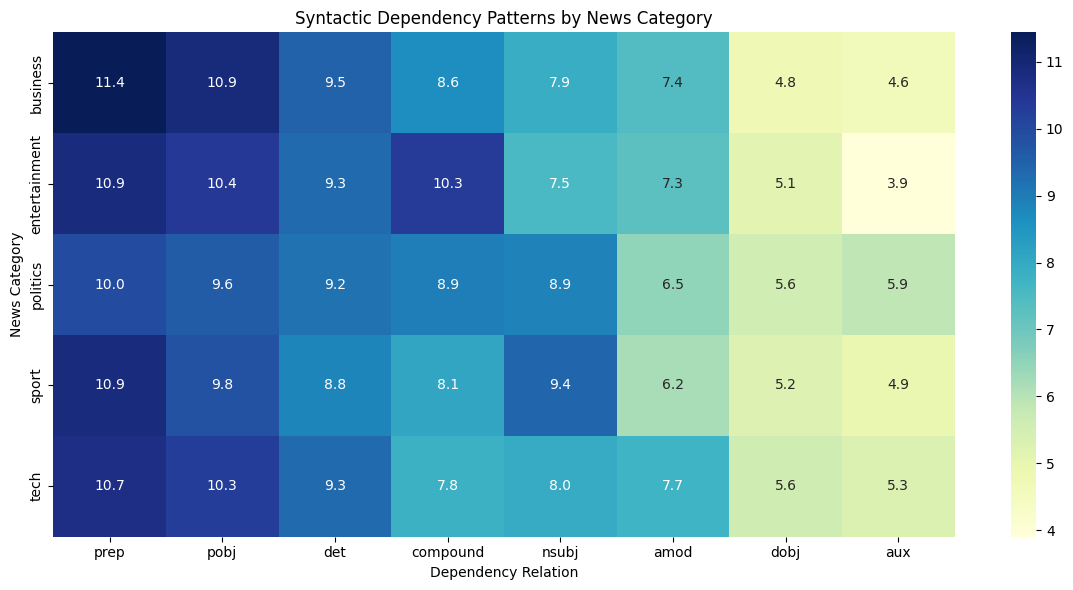

In [48]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select the 8 most common dependency relations overall
top_dependencies = (
    syntax_df["Dependency"]
    .value_counts()
    .head(8)
    .index
)

dependency_percentages = pd.crosstab(
    syntax_df["Category"],
    syntax_df["Dependency"],
    normalize="index"
) * 100

# Keep the same top dependencies for the visualization
plot_data = dependency_percentages[
    top_dependencies
]

plt.figure(figsize=(12, 6))

sns.heatmap(
    plot_data,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu"
)

plt.title("Syntactic Dependency Patterns by News Category")
plt.xlabel("Dependency Relation")
plt.ylabel("News Category")
plt.tight_layout()
plt.show()

,Category,Average Sentiment Score
0,politics,0.060
1,business,0.247
2,tech,0.534
3,sport,0.565
4,entertainment,0.601


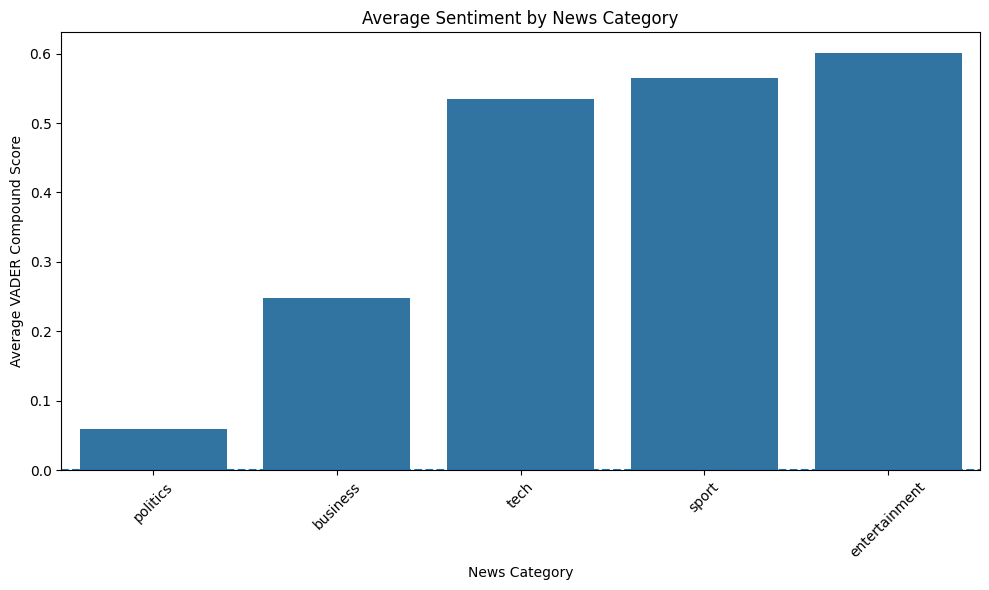

In [49]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate average sentiment for each category
sentiment_comparison = (
    df_clean.groupby("Category")["Sentiment_Compound"]
    .mean()
    .sort_values()
)

display(
    sentiment_comparison.reset_index(
        name="Average Sentiment Score"
    ).round(3)
)

# Visualize the comparison
plt.figure(figsize=(10, 6))

sns.barplot(
    x=sentiment_comparison.index,
    y=sentiment_comparison.values
)

plt.axhline(0, linestyle="--")
plt.title("Average Sentiment by News Category")
plt.xlabel("News Category")
plt.ylabel("Average VADER Compound Score")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [50]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, accuracy_score
import pandas as pd

tfidf_configs = [
    {"max_features": 1000, "min_df": 2, "max_df": 0.95},
    {"max_features": 3000, "min_df": 2, "max_df": 0.95},
    {"max_features": 5000, "min_df": 2, "max_df": 0.95}
]

tfidf_results = []

for config in tfidf_configs:
    vectorizer = TfidfVectorizer(**config)

    train_vectors = vectorizer.fit_transform(X_train)
    test_vectors = vectorizer.transform(X_test)

    model = LogisticRegression(max_iter=1000, random_state=42)
    model.fit(train_vectors, y_train)
    predictions = model.predict(test_vectors)

    tfidf_results.append({
        "Max Features": config["max_features"],
        "Accuracy": round(accuracy_score(y_test, predictions), 4),
        "Weighted F1": round(
            f1_score(y_test, predictions, average="weighted"), 4
        )
    })

tfidf_comparison = pd.DataFrame(tfidf_results)
display(tfidf_comparison)

,Max Features,Accuracy,Weighted F1
0,1000,0.9549,0.9544
1,3000,0.9583,0.9581
2,5000,0.9618,0.9615


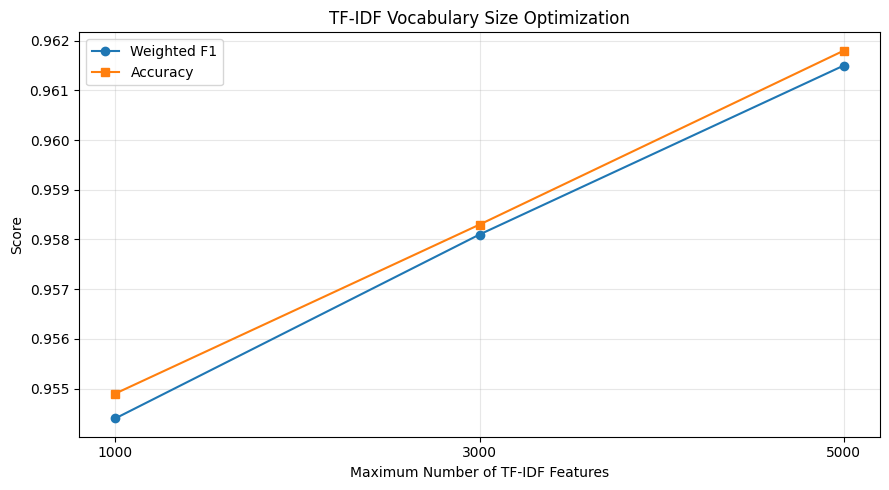

Best TF-IDF feature count: 5000.0
Best weighted F1: 0.9615


In [51]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    tfidf_comparison["Max Features"],
    tfidf_comparison["Weighted F1"],
    marker="o",
    label="Weighted F1"
)

plt.plot(
    tfidf_comparison["Max Features"],
    tfidf_comparison["Accuracy"],
    marker="s",
    label="Accuracy"
)

plt.title("TF-IDF Vocabulary Size Optimization")
plt.xlabel("Maximum Number of TF-IDF Features")
plt.ylabel("Score")
plt.xticks(tfidf_comparison["Max Features"])
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

best_tfidf_row = tfidf_comparison.loc[
    tfidf_comparison["Weighted F1"].idxmax()
]

print("Best TF-IDF feature count:", best_tfidf_row["Max Features"])
print("Best weighted F1:", best_tfidf_row["Weighted F1"])

In [53]:
# Use the optimized model's learned coefficients
feature_names = vectorizer.get_feature_names_out()
coefficients = best_model.coef_
classes = best_model.classes_

for i, category in enumerate(classes):
    top_indices = coefficients[i].argsort()[-10:][::-1]

    print(f"\nTop words for {category}:")
    display(pd.DataFrame({
        "Word": feature_names[top_indices],
        "Coefficient": coefficients[i][top_indices].round(4)
    }))


Top words for business:


,Word,Coefficient
0,firm,3.6831
1,company,3.6791
2,bank,3.4083
3,economic,2.6130
4,share,2.5600
5,investment,2.4851
6,economy,2.4704
7,profit,2.4212
8,market,2.3996
9,price,2.2551



Top words for entertainment:


,Word,Coefficient
0,film,5.6381
1,show,3.9505
2,music,3.1876
3,star,3.0758
4,singer,2.8390
5,album,2.8198
6,band,2.7239
7,actor,2.4769
8,tv,2.3140
9,award,1.9385



Top words for politics:


,Word,Coefficient
0,mr,3.8289
1,labour,3.3211
2,blair,3.2718
3,party,3.2304
4,minister,3.1802
5,government,2.8345
6,election,2.8299
7,mp,2.7008
8,secretary,2.5464
9,child,2.4683



Top words for sport:


,Word,Coefficient
0,match,2.7999
1,player,2.6621
2,champion,2.5856
3,coach,2.4550
4,club,2.4050
5,win,2.3835
6,injury,2.1751
7,england,2.1745
8,cup,2.1615
9,season,2.1492



Top words for tech:


,Word,Coefficient
0,technology,3.5273
1,computer,3.0954
2,online,3.0232
3,software,3.0183
4,mobile,2.9301
5,user,2.8591
6,people,2.6638
7,service,2.4870
8,phone,2.3915
9,digital,2.3673


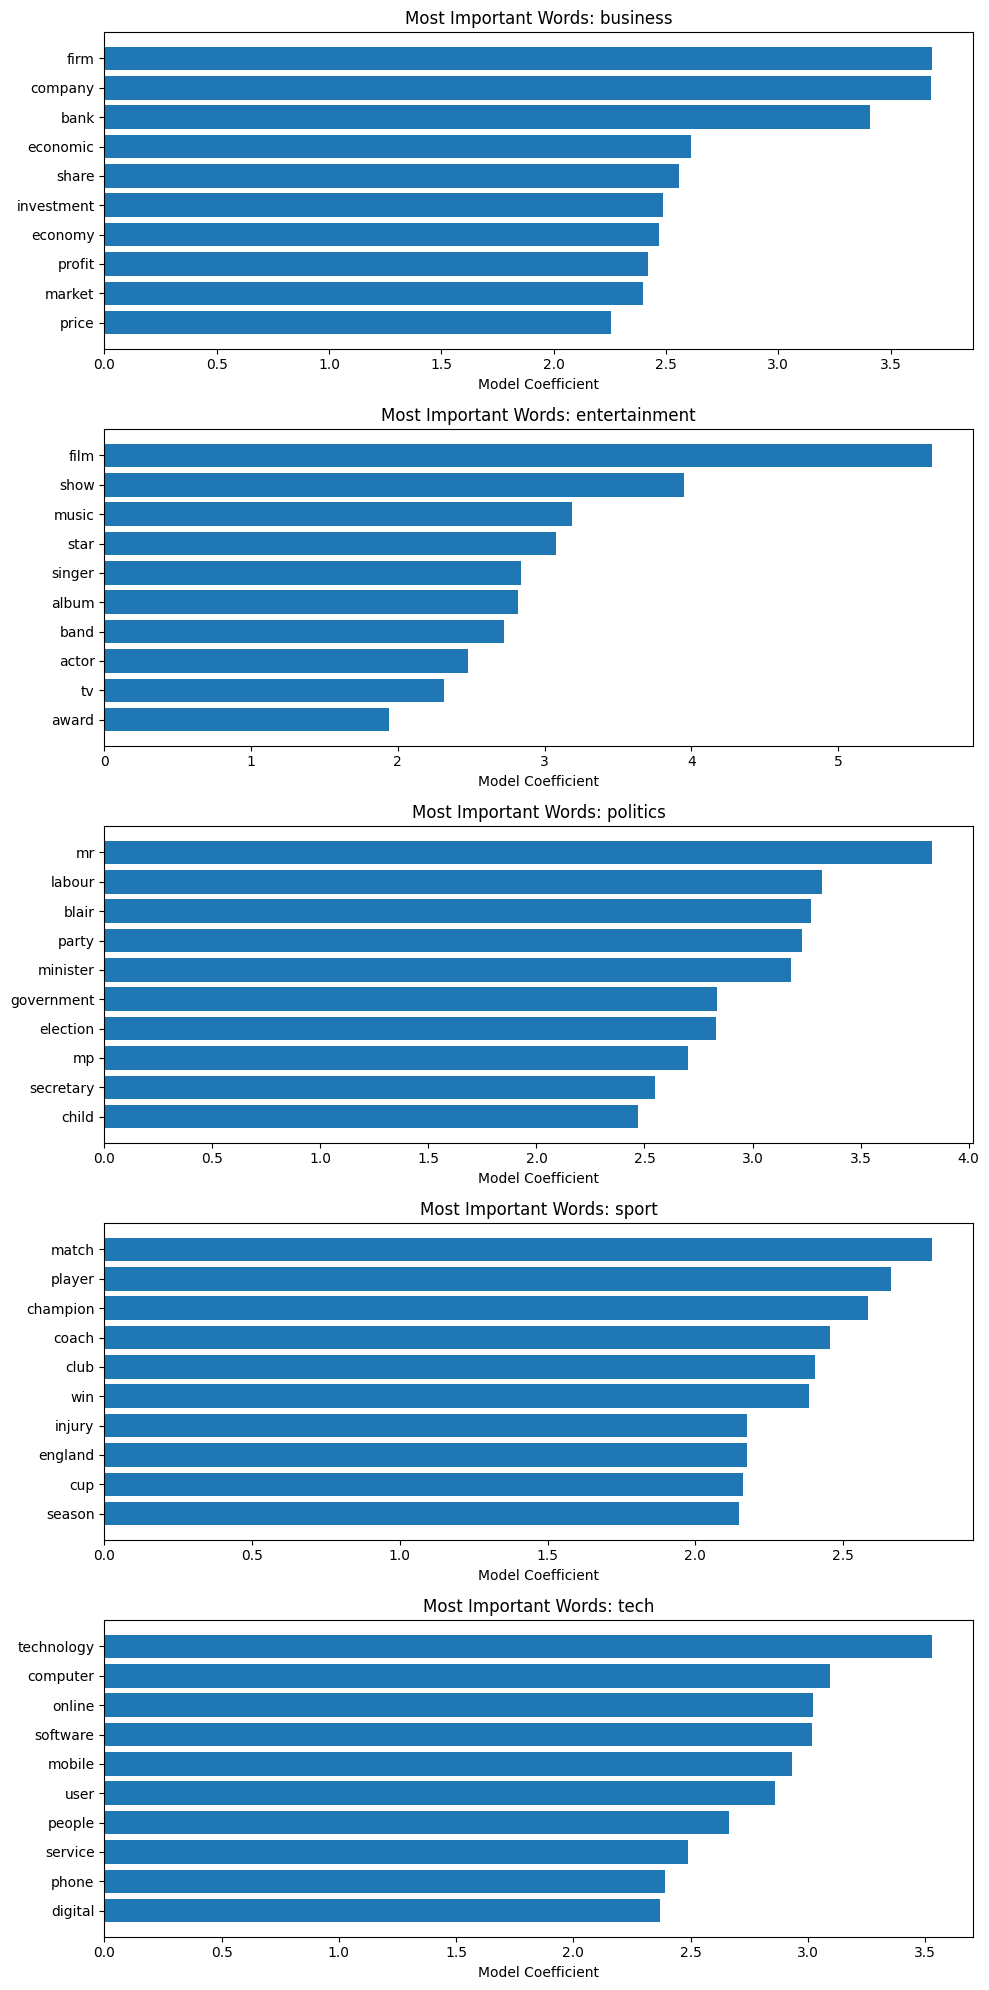

In [54]:
import matplotlib.pyplot as plt
import pandas as pd

feature_names = vectorizer.get_feature_names_out()
coefficients = best_model.coef_
classes = best_model.classes_

fig, axes = plt.subplots(
    nrows=len(classes),
    ncols=1,
    figsize=(10, 4 * len(classes))
)

for i, category in enumerate(classes):
    top_indices = coefficients[i].argsort()[-10:]

    words = feature_names[top_indices]
    scores = coefficients[i][top_indices]

    axes[i].barh(words, scores)
    axes[i].set_title(f"Most Important Words: {category}")
    axes[i].set_xlabel("Model Coefficient")

plt.tight_layout()
plt.show()

In [55]:
from sklearn.metrics import classification_report
import pandas as pd

report = classification_report(
    y_test,
    optimized_pred,
    output_dict=True,
    zero_division=0
)

performance_by_category = pd.DataFrame(report).T

display(
    performance_by_category.loc[
        sorted(y_test.unique()),
        ["precision", "recall", "f1-score", "support"]
    ].round(3)
)

,precision,recall,f1-score,support
business,0.930,0.985,0.957,67.0
entertainment,1.000,0.962,0.981,53.0
politics,0.980,0.943,0.962,53.0
sport,0.944,1.000,0.971,68.0
tech,0.977,0.894,0.933,47.0


In [56]:
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

project_summary = pd.DataFrame({
    "Metric": [
        "Total articles analyzed",
        "Unique news categories",
        "Training articles",
        "Test articles",
        "Optimized model accuracy",
        "Optimized model weighted F1",
        "Articles incorrectly classified"
    ],
    "Result": [
        len(df_clean),
        df_clean["Category"].nunique(),
        len(X_train),
        len(X_test),
        round(accuracy_score(y_test, optimized_pred), 4),
        round(f1_score(y_test, optimized_pred, average="weighted"), 4),
        len(errors)
    ]
})

display(project_summary)

,Metric,Result
0,Total articles analyzed,1440.0000
1,Unique news categories,5.0000
2,Training articles,1152.0000
3,Test articles,288.0000
4,Optimized model accuracy,0.9618
5,Optimized model weighted F1,0.9616
6,Articles incorrectly classified,11.0000


In [57]:
# Final dataset quality checks
print("DATASET QUALITY REPORT")
print("-" * 35)

print("Total articles:", len(df_clean))
print("Unique categories:", df_clean["Category"].nunique())
print("Categories:", sorted(df_clean["Category"].unique()))

print("\nMissing values:")
display(df_clean[["Text", "Category", "Processed_Text"]].isnull().sum())

print("\nDuplicate article texts:", df_clean["Text"].duplicated().sum())

print(
    "Empty processed articles:",
    (df_clean["Processed_Text"].str.strip() == "").sum()
)

print("\nArticles per category:")
display(df_clean["Category"].value_counts().rename("Article Count"))

DATASET QUALITY REPORT
-----------------------------------
Total articles: 1440
Unique categories: 5
Categories: ['business', 'entertainment', 'politics', 'sport', 'tech']

Missing values:


,0
Text,0
Category,0
Processed_Text,0



Duplicate article texts: 0
Empty processed articles: 0

Articles per category:


,Article Count
Category,
sport,342
business,335
politics,266
entertainment,263
tech,234


In [58]:
# NewsBot project completion audit

required_outputs = {
    "Text preprocessing": "Processed_Text",
    "POS tagging": None,
    "TF-IDF analysis": None,
    "Sentiment analysis": "Sentiment_Compound",
    "Emotion analysis": "Joy",
    "Named entity extraction": "Entities",
}

print("NEWSBOT PROJECT AUDIT")
print("-" * 40)

for task, column in required_outputs.items():
    if column is None:
        print(f"{task}: Review existing output")
    else:
        print(
            f"{task}:",
            "Available" if column in df_clean.columns else "Missing"
        )

print("\nClassification outputs:")
print("Original Logistic Regression:", "Available" if "y_pred" in globals() else "Missing")
print("Naive Bayes:", "Available" if "nb_pred" in globals() else "Missing")
print("Optimized Logistic Regression:", "Available" if "optimized_pred" in globals() else "Missing")

print("\nSyntax analysis:", "Available" if "syntax_df" in globals() else "Missing")
print("Semantic role analysis:", "Available" if "semantic_roles_df" in globals() else "Missing")
print("Entity frequency analysis:", "Available" if "entity_df" in globals() else "Missing")

NEWSBOT PROJECT AUDIT
----------------------------------------
Text preprocessing: Available
POS tagging: Review existing output
TF-IDF analysis: Review existing output
Sentiment analysis: Available
Emotion analysis: Available
Named entity extraction: Available

Classification outputs:
Original Logistic Regression: Available
Naive Bayes: Available
Optimized Logistic Regression: Available

Syntax analysis: Available
Semantic role analysis: Missing
Entity frequency analysis: Available


# ITAI 2373 Midterm Project: NewsBot Intelligence System

## Project Overview

The NewsBot Intelligence System uses Natural Language Processing (NLP) and machine learning to analyze and classify news articles into five categories: Business, Entertainment, Politics, Sport, and Tech.

## Project Objectives

- Clean and preprocess raw news article text.
- Explore important terms using TF-IDF.
- Analyze parts of speech and grammatical dependencies.
- Examine sentiment and emotion-related language.
- Extract named entities such as people, organizations, and locations.
- Train, evaluate, and optimize multiclass text classification models.
- Compare model performance and investigate classification errors.

## Dataset

This project uses the BBC News Classification dataset. The notebook includes data cleaning, duplicate removal, text preprocessing, and exploratory analysis.

## Methods

The project applies text preprocessing, TF-IDF feature extraction, POS tagging, syntactic dependency analysis, sentiment analysis, emotion-word matching, named entity recognition, and multiclass classification.

Logistic Regression and Multinomial Naive Bayes are compared, with additional hyperparameter tuning to evaluate potential improvements.

## Evaluation

The classification models are evaluated using accuracy, weighted precision, weighted recall, weighted F1-score, and a confusion matrix. Category-level performance and misclassified articles are also examined.

## Limitations

Sentiment and emotion-word counts are exploratory indicators, not definitive interpretations of an article's meaning. Semantic roles are approximated using grammatical dependencies, and classification results depend on the dataset and experimental settings.

## Conclusion

This project demonstrates how NLP and machine learning can support automated news categorization and text analysis. The results provide a foundation for a news intelligence tool that can organize articles and explore language patterns across categories.
